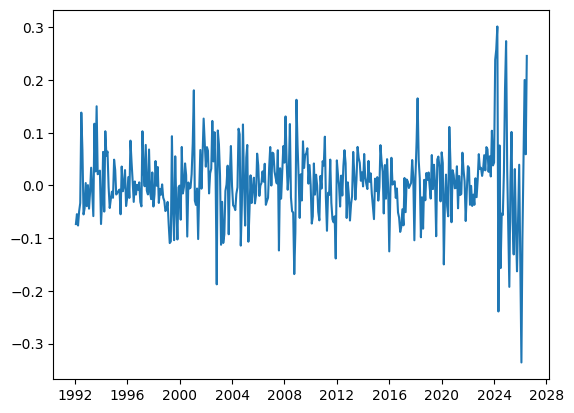

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("data/raw/PCOCOUSDM.csv",parse_dates=["observation_date"],index_col=["observation_date"])
df['natural_log']= np.log(df['PCOCOUSDM'])
df['log_change']= df['natural_log'].diff()
fig1 = plt.plot(df['log_change'])
df.index = df.index.to_period("M")



200


<Axes: >

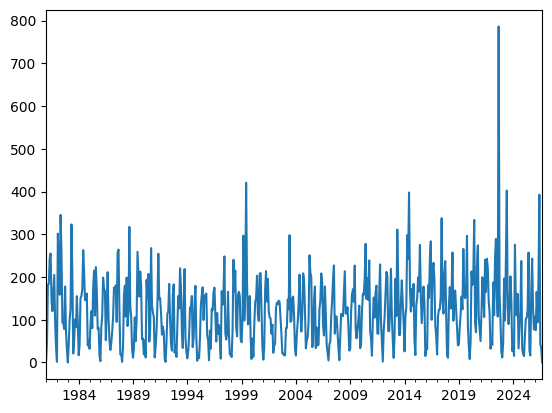

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests 

beURL = "https://power.larc.nasa.gov/api/temporal/daily/point"
params = {"parameters": "PRECTOTCORR",
    "community": "AG",
    "longitude": -5.96,
    "latitude": 6.13,
    "start": "19810101",
    "end": "20260901",
    "format": "JSON"}
response = requests.get(beURL, params=params)
print(response.status_code)
raw = response.json()
rain = pd.Series(raw['properties']['parameter']['PRECTOTCORR'])
rain.index  = pd.to_datetime(rain.index, format='%Y%m%d') 
rain = rain.resample("ME").sum()
rain = rain.to_period("M")
rain.plot()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests 

town_point_dict={"Gagnoa":[6.13,-5.95], "San-Pedro":[4.76,-6.64],"Soubré":[5.78,-6.59],
                "Daloa":[6.87,-6.45],
                "Sefwi Wiawso":[6.21,-2.49],"Assin Fosu":[5.7,-1.28],"Goaso":[6.8,-2.52],
                "Bekwai":[6.45,-1.58]}
def point_collection(coords):
    beURL = "https://power.larc.nasa.gov/api/temporal/daily/point"
    params = {"parameters": "PRECTOTCORR",
        "community": "AG",
        "longitude": coords[1],
        "latitude": coords[0],
        "start": "19810101",
        "end": "20260228",
        "format": "JSON"}
    response = requests.get(beURL, params=params)
    print(response.status_code)
    raw = response.json()
    rain = pd.Series(raw['properties']['parameter']['PRECTOTCORR'])
    rain.index  = pd.to_datetime(rain.index, format='%Y%m%d') 
    rain = rain.resample("ME").sum()
    rain = rain.to_period("M")
    return rain


rain_per_region={}
for region,coords in town_point_dict.items():
    rain_per_region[region] = point_collection(coords)

rain_per_region  = pd.concat(rain_per_region, axis="columns")
mean_per_region = rain_per_region.mean(axis=1)
mean_per_month= mean_per_region.groupby(mean_per_region.index.month).transform('mean')
std_per_month = mean_per_region.groupby(mean_per_region.index.month).transform('std')
rain_anomaly = (mean_per_region - mean_per_month)/std_per_month
abs_anomaly = rain_anomaly.abs()
pd.concat([abs_anomaly, df['PCOCOUSDM']],keys=["rain","price"], axis =1)

200
200
200
200
200
200
200
200


,rain,price
1981-01,0.640293,NaN
1981-02,0.036896,NaN
1981-03,1.663897,NaN
1981-04,0.232656,NaN
1981-05,2.099395,NaN
...,...,...
2026-03,NaN,3241.488951
2026-04,NaN,3392.143554
2026-05,NaN,4142.973093
2026-06,NaN,4395.458432


In [3]:
price_rain_merge= pd.concat([rain_anomaly,abs_anomaly, df['log_change']],keys=["rain","abs_rain","price_change"], axis =1)
lag="Lag"
absolute = "Abs"
for i in range (1,7):
   price_rain_merge["rain"+lag + str(i) ] = price_rain_merge["rain"].shift(i, freq = "M") 
   price_rain_merge["abs"+lag + str(i) ] = price_rain_merge["abs_rain"].shift(i, freq = "M") 




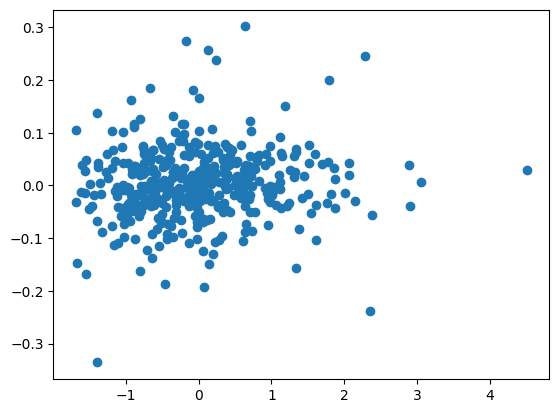

In [6]:
fig4=plt.scatter(x= price_rain_merge["rainLag6"],y=price_rain_merge["price_change"])

In [4]:
import statsmodels.api as sm
sample = price_rain_merge.loc["1992-02":"2026-02"]

def regression(frame, column, maxlags):
    clean = frame[["price_change", column]].dropna()
    X = sm.add_constant(clean[column])
    model = sm.OLS(clean["price_change"], X).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return pd.Series({"coef": model.params[column], "std_err": model.bse[column],
                      "p": model.pvalues[column], "r2": model.rsquared, "n": model.nobs})

columns = ["rain"]
for i in range(1, 7):
    columns.append("rain" + lag + str(i))
columns.append("abs_rain")
for i in range(1, 7):
    columns.append("abs" + lag + str(i))

results = {}
for column in columns:
    results[column] = regression(sample, column, 5)
results = pd.concat(results, axis="columns").T
results.round(4)

,coef,std_err,p,r2,n
rain,-0.0038,0.0048,0.4226,0.0026,409.0
rainLag1,-0.0048,0.0053,0.3679,0.0041,409.0
rainLag2,-0.0002,0.0049,0.9748,0.0000,409.0
rainLag3,0.0051,0.0052,0.3214,0.0046,409.0
rainLag4,-0.0020,0.0041,0.6299,0.0007,409.0
rainLag5,0.0088,0.0058,0.1307,0.0134,409.0
rainLag6,0.0037,0.0043,0.3809,0.0024,409.0
abs_rain,0.0071,0.0081,0.3852,0.0035,409.0
absLag1,0.0153,0.0092,0.0955,0.0163,409.0
absLag2,0.0045,0.0074,0.5430,0.0014,409.0


In [6]:
season_rain = mean_per_region[mean_per_region.index.month.isin([4, 5, 6, 7, 8])]
season_rain = season_rain.groupby(season_rain.index.year).sum()
season_anomaly = (season_rain - season_rain.mean()) / season_rain.std()
abs_season_anomaly = season_anomaly.abs()

september = df['natural_log'][df.index.month == 9]
february = df['natural_log'][df.index.month == 2]
september.index = september.index.year
february.index = february.index.year - 1
season_price = february - september

season_merge = pd.concat([season_anomaly, abs_season_anomaly, season_price], keys=["rain", "abs_rain", "price_change"], axis=1).dropna()
season_results = pd.concat({"rain": regression(season_merge, "rain", 0), "abs_rain": regression(season_merge, "abs_rain", 0)}, axis="columns").T
season_results.round(4)

,coef,std_err,p,r2,n
rain,0.0441,0.0459,0.3375,0.0343,34.0
abs_rain,0.0828,0.0734,0.2591,0.0441,34.0


In [7]:
no_drought = sample[~sample.index.year.isin([2023, 2024])]
results_no_drought = {}
for column in columns:
    results_no_drought[column] = regression(no_drought, column, 5)
results_no_drought = pd.concat(results_no_drought, axis="columns").T

season_no_drought = season_merge.drop([2022, 2023, 2024])
season_results_no_drought = pd.concat({"rain": regression(season_no_drought, "rain", 0), "abs_rain": regression(season_no_drought, "abs_rain", 0)}, axis="columns").T
print(season_results_no_drought.round(4))
results_no_drought.round(4)

            coef  std_err       p      r2     n
rain      0.0142   0.0389  0.7148  0.0031  31.0
abs_rain -0.0356   0.0680  0.6010  0.0071  31.0


,coef,std_err,p,r2,n
rain,-0.0078,0.0047,0.0930,0.0126,385.0
rainLag1,-0.0122,0.0044,0.0050,0.0305,385.0
rainLag2,-0.0030,0.0042,0.4726,0.0018,385.0
rainLag3,-0.0004,0.0043,0.9243,0.0000,385.0
rainLag4,-0.0031,0.0032,0.3450,0.0018,385.0
rainLag5,0.0057,0.0048,0.2312,0.0061,385.0
rainLag6,0.0054,0.0040,0.1757,0.0056,385.0
abs_rain,0.0000,0.0076,0.9995,0.0000,385.0
absLag1,0.0047,0.0076,0.5319,0.0017,385.0
absLag2,0.0014,0.0069,0.8347,0.0002,385.0
